In [14]:
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna


c:\Users\samya\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv(r"C:\Users\samya\OneDrive\Documents\GitHub\AirlinePricePredictor\truncated3.csv")

In [3]:
df.describe()

,elapsedDays,baseFare,totalFare,seatsRemaining,totalTravelDistance
count,600000.000000,600000.00000,600000.000000,600000.000000,563269.000000
mean,0.146782,303.84388,352.199129,5.598443,1576.614923
std,0.353898,220.35365,236.477821,2.946632,834.780884
min,0.000000,5.10000,23.970000,0.000000,97.000000
25%,0.000000,164.65000,199.100000,3.000000,872.000000
50%,0.000000,264.19000,312.600000,7.000000,1398.000000
75%,0.000000,394.42000,448.600000,8.000000,2345.000000
max,2.000000,3531.16000,3810.600000,10.000000,3958.000000


In [4]:
pd.set_option('display.max.columns', 40)


In [6]:
def parse_duration_to_minutes(duration_str):
    if pd.isna(duration_str):
        return None
    
    hours_match = re.search(r'(\d+)H', str(duration_str))
    minutes_match = re.search(r'(\d+)M', str(duration_str))
    
    hours = int(hours_match.group(1)) if hours_match else 0
    minutes = int(minutes_match.group(1)) if minutes_match else 0
    
    return hours * 60 + minutes

In [6]:
df['duration_minutes'] = df['travelDuration'].apply(parse_duration_to_minutes)


In [7]:
df

,legId,searchDate,flightDate,startingAirport,destinationAirport,fareBasisCode,travelDuration,elapsedDays,isBasicEconomy,isRefundable,isNonStop,baseFare,totalFare,seatsRemaining,totalTravelDistance,segmentsDepartureTimeEpochSeconds,segmentsDepartureTimeRaw,segmentsArrivalTimeEpochSeconds,segmentsArrivalTimeRaw,segmentsArrivalAirportCode,segmentsDepartureAirportCode,segmentsAirlineName,segmentsAirlineCode,segmentsEquipmentDescription,segmentsDurationInSeconds,segmentsDistance,segmentsCabinCode,duration_minutes
0,9ca0e81111c683bec1012473feefd28f,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H29M,0,False,False,True,217.67,248.6,9,947.0,1650214620,2022-04-17T12:57:00.000-04:00,1650223560,2022-04-17T15:26:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,8940,947,coach,149
1,98685953630e772a098941b71906592b,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H30M,0,False,False,True,217.67,248.6,4,947.0,1650191400,2022-04-17T06:30:00.000-04:00,1650200400,2022-04-17T09:00:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9000,947,coach,150
2,98d90cbc32bfbb05c2fc32897c7c1087,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H30M,0,False,False,True,217.67,248.6,9,947.0,1650209700,2022-04-17T11:35:00.000-04:00,1650218700,2022-04-17T14:05:00.000-04:00,BOS,ATL,Delta,DL,Boeing 757-200,9000,947,coach,150
3,969a269d38eae583f455486fa90877b4,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H32M,0,False,False,True,217.67,248.6,8,947.0,1650218340,2022-04-17T13:59:00.000-04:00,1650227460,2022-04-17T16:31:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9120,947,coach,152
4,980370cf27c89b40d2833a1d5afc9751,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H34M,0,False,False,True,217.67,248.6,9,947.0,1650203940,2022-04-17T09:59:00.000-04:00,1650213180,2022-04-17T12:33:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9240,947,coach,154
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599995,d0b8831871406770573d3d47520d195e,2022-04-17,2022-06-14,IAD,BOS,SAA0OFEN,PT1H41M,0,False,False,True,115.35,138.6,7,406.0,1655210040,2022-06-14T08:34:00.000-04:00,1655216100,2022-06-14T10:15:00.000-04:00,BOS,IAD,United,UA,Boeing 737 MAX 9,6060,406,coach,101
599996,b909fd1eb1b1caebff139147e7b5987e,2022-04-17,2022-06-14,IAD,BOS,WAA1JFEN,PT1H38M,0,False,False,True,127.44,151.6,2,406.0,1655225160,2022-06-14T12:46:00.000-04:00,1655231040,2022-06-14T14:24:00.000-04:00,BOS,IAD,United,UA,Boeing 737-900,5880,406,coach,98
599997,aa1fac36237180027a6cd4aa25f829e9,2022-04-17,2022-06-14,IAD,BOS,XAVNA0BQ,PT8H57M,0,True,False,False,114.42,152.2,9,406.0,1655200800||1655227860,2022-06-14T06:00:00.000-04:00||2022-06-14T13:3...,1655206080||1655233020,2022-06-14T07:28:00.000-04:00||2022-06-14T14:5...,JFK||BOS,IAD||JFK,Delta||Delta,DL||DL,Embraer 175||Airbus A220-100,5280||5160,221||185,coach||coach,537
599998,0665c042ce293b362bf5fd04a42b7168,2022-04-17,2022-06-14,IAD,BOS,GVAGZNN1,PT5H10M,0,False,False,False,134.88,167.1,7,1055.0,1655198400||1655209500,2022-06-14T05:20:00.000-04:00||2022-06-14T08:2...,1655203140||1655217000,2022-06-14T06:39:00.000-04:00||2022-06-14T10:3...,CLT||BOS,IAD||CLT,American Airlines||American Airlines,AA||AA,Boeing 737-800||Airbus A320,4740||7500,327||728,coach||coach,310


In [8]:
def categorize_stops(airline_string):
    if pd.isna(airline_string):
        return None
    
    segments = len(str(airline_string).split('||'))
    return segments - 1



In [9]:
df

,legId,searchDate,flightDate,startingAirport,destinationAirport,fareBasisCode,travelDuration,elapsedDays,isBasicEconomy,isRefundable,isNonStop,baseFare,totalFare,seatsRemaining,totalTravelDistance,segmentsDepartureTimeEpochSeconds,segmentsDepartureTimeRaw,segmentsArrivalTimeEpochSeconds,segmentsArrivalTimeRaw,segmentsArrivalAirportCode,segmentsDepartureAirportCode,segmentsAirlineName,segmentsAirlineCode,segmentsEquipmentDescription,segmentsDurationInSeconds,segmentsDistance,segmentsCabinCode,duration_minutes,Num_of_stops
0,9ca0e81111c683bec1012473feefd28f,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H29M,0,False,False,True,217.67,248.6,9,947.0,1650214620,2022-04-17T12:57:00.000-04:00,1650223560,2022-04-17T15:26:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,8940,947,coach,149,0
1,98685953630e772a098941b71906592b,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H30M,0,False,False,True,217.67,248.6,4,947.0,1650191400,2022-04-17T06:30:00.000-04:00,1650200400,2022-04-17T09:00:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9000,947,coach,150,0
2,98d90cbc32bfbb05c2fc32897c7c1087,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H30M,0,False,False,True,217.67,248.6,9,947.0,1650209700,2022-04-17T11:35:00.000-04:00,1650218700,2022-04-17T14:05:00.000-04:00,BOS,ATL,Delta,DL,Boeing 757-200,9000,947,coach,150,0
3,969a269d38eae583f455486fa90877b4,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H32M,0,False,False,True,217.67,248.6,8,947.0,1650218340,2022-04-17T13:59:00.000-04:00,1650227460,2022-04-17T16:31:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9120,947,coach,152,0
4,980370cf27c89b40d2833a1d5afc9751,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H34M,0,False,False,True,217.67,248.6,9,947.0,1650203940,2022-04-17T09:59:00.000-04:00,1650213180,2022-04-17T12:33:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9240,947,coach,154,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599995,d0b8831871406770573d3d47520d195e,2022-04-17,2022-06-14,IAD,BOS,SAA0OFEN,PT1H41M,0,False,False,True,115.35,138.6,7,406.0,1655210040,2022-06-14T08:34:00.000-04:00,1655216100,2022-06-14T10:15:00.000-04:00,BOS,IAD,United,UA,Boeing 737 MAX 9,6060,406,coach,101,0
599996,b909fd1eb1b1caebff139147e7b5987e,2022-04-17,2022-06-14,IAD,BOS,WAA1JFEN,PT1H38M,0,False,False,True,127.44,151.6,2,406.0,1655225160,2022-06-14T12:46:00.000-04:00,1655231040,2022-06-14T14:24:00.000-04:00,BOS,IAD,United,UA,Boeing 737-900,5880,406,coach,98,0
599997,aa1fac36237180027a6cd4aa25f829e9,2022-04-17,2022-06-14,IAD,BOS,XAVNA0BQ,PT8H57M,0,True,False,False,114.42,152.2,9,406.0,1655200800||1655227860,2022-06-14T06:00:00.000-04:00||2022-06-14T13:3...,1655206080||1655233020,2022-06-14T07:28:00.000-04:00||2022-06-14T14:5...,JFK||BOS,IAD||JFK,Delta||Delta,DL||DL,Embraer 175||Airbus A220-100,5280||5160,221||185,coach||coach,537,1
599998,0665c042ce293b362bf5fd04a42b7168,2022-04-17,2022-06-14,IAD,BOS,GVAGZNN1,PT5H10M,0,False,False,False,134.88,167.1,7,1055.0,1655198400||1655209500,2022-06-14T05:20:00.000-04:00||2022-06-14T08:2...,1655203140||1655217000,2022-06-14T06:39:00.000-04:00||2022-06-14T10:3...,CLT||BOS,IAD||CLT,American Airlines||American Airlines,AA||AA,Boeing 737-800||Airbus A320,4740||7500,327||728,coach||coach,310,1


In [10]:
df = df.drop(['legId','searchDate','flightDate','fareBasisCode','travelDuration','segmentsDepartureTimeEpochSeconds','segmentsDepartureTimeRaw','segmentsArrivalTimeEpochSeconds','segmentsArrivalTimeRaw','segmentsArrivalAirportCode','segmentsDepartureAirportCode','segmentsAirlineName','segmentsAirlineCode','segmentsEquipmentDescription','segmentsDurationInSeconds','segmentsDistance','segmentsCabinCode'], axis = 1)

In [11]:
df

,startingAirport,destinationAirport,elapsedDays,isBasicEconomy,isRefundable,isNonStop,baseFare,totalFare,seatsRemaining,totalTravelDistance,duration_minutes,Num_of_stops
0,ATL,BOS,0,False,False,True,217.67,248.6,9,947.0,149,0
1,ATL,BOS,0,False,False,True,217.67,248.6,4,947.0,150,0
2,ATL,BOS,0,False,False,True,217.67,248.6,9,947.0,150,0
3,ATL,BOS,0,False,False,True,217.67,248.6,8,947.0,152,0
4,ATL,BOS,0,False,False,True,217.67,248.6,9,947.0,154,0
...,...,...,...,...,...,...,...,...,...,...,...,...
599995,IAD,BOS,0,False,False,True,115.35,138.6,7,406.0,101,0
599996,IAD,BOS,0,False,False,True,127.44,151.6,2,406.0,98,0
599997,IAD,BOS,0,True,False,False,114.42,152.2,9,406.0,537,1
599998,IAD,BOS,0,False,False,False,134.88,167.1,7,1055.0,310,1


In [12]:
df.startingAirport.value_counts()

startingAirport
LAX    59052
LGA    46334
BOS    43561
DFW    41604
SFO    40659
ORD    40376
CLT    39122
ATL    38969
MIA    38309
PHL    34975
DTW    34442
DEN    34410
EWR    31300
JFK    28658
IAD    25028
OAK    23201
Name: count, dtype: int64

In [13]:
df.destinationAirport.value_counts()

destinationAirport
LAX    57669
LGA    46211
DFW    42658
MIA    41822
ORD    41104
BOS    40763
ATL    40641
SFO    39408
CLT    38801
DEN    36471
DTW    34166
PHL    32519
EWR    31166
JFK    29674
IAD    24215
OAK    22712
Name: count, dtype: int64

In [15]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

In [15]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

encoded_values = encoder.fit_transform(df[['startingAirport','destinationAirport']])
new_col = encoder.get_feature_names_out(['startingAirport','destinationAirport'])

df_encoded = pd.DataFrame(encoded_values, columns=new_col, index=df.index)

data_final = pd.concat(
    [df.drop(columns=['startingAirport','destinationAirport']), df_encoded],
    axis = 1
)

In [16]:
data_final

,elapsedDays,isBasicEconomy,isRefundable,isNonStop,baseFare,totalFare,seatsRemaining,totalTravelDistance,duration_minutes,Num_of_stops,startingAirport_ATL,startingAirport_BOS,startingAirport_CLT,startingAirport_DEN,startingAirport_DFW,startingAirport_DTW,startingAirport_EWR,startingAirport_IAD,startingAirport_JFK,startingAirport_LAX,...,startingAirport_OAK,startingAirport_ORD,startingAirport_PHL,startingAirport_SFO,destinationAirport_ATL,destinationAirport_BOS,destinationAirport_CLT,destinationAirport_DEN,destinationAirport_DFW,destinationAirport_DTW,destinationAirport_EWR,destinationAirport_IAD,destinationAirport_JFK,destinationAirport_LAX,destinationAirport_LGA,destinationAirport_MIA,destinationAirport_OAK,destinationAirport_ORD,destinationAirport_PHL,destinationAirport_SFO
0,0,False,False,True,217.67,248.6,9,947.0,149,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,False,False,True,217.67,248.6,4,947.0,150,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,False,False,True,217.67,248.6,9,947.0,150,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,False,False,True,217.67,248.6,8,947.0,152,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,False,False,True,217.67,248.6,9,947.0,154,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599995,0,False,False,True,115.35,138.6,7,406.0,101,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599996,0,False,False,True,127.44,151.6,2,406.0,98,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599997,0,True,False,False,114.42,152.2,9,406.0,537,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599998,0,False,False,False,134.88,167.1,7,1055.0,310,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
columns_to_encode = ['isBasicEconomy','isRefundable','isNonStop']

for col in columns_to_encode:
    data_final[col] = data_final[col].astype(int)

In [18]:
data_final.describe

<bound method NDFrame.describe of         elapsedDays  isBasicEconomy  isRefundable  isNonStop  baseFare  \
0                 0               0             0          1    217.67   
1                 0               0             0          1    217.67   
2                 0               0             0          1    217.67   
3                 0               0             0          1    217.67   
4                 0               0             0          1    217.67   
...             ...             ...           ...        ...       ...   
599995            0               0             0          1    115.35   
599996            0               0             0          1    127.44   
599997            0               1             0          0    114.42   
599998            0               0             0          0    134.88   
599999            0               0             0          0    134.88   

        totalFare  seatsRemaining  totalTravelDistance  duration_minutes  \
0

In [19]:
columns_with_nan = data_final.columns[data_final.isnull().any()].tolist()
print(f"\nColumns with NaN: {columns_with_nan}")
print("NaN values per column:")
print(data_final.isnull().sum())


Columns with NaN: ['totalTravelDistance']
NaN values per column:
elapsedDays                   0
isBasicEconomy                0
isRefundable                  0
isNonStop                     0
baseFare                      0
totalFare                     0
seatsRemaining                0
totalTravelDistance       36731
duration_minutes              0
Num_of_stops                  0
startingAirport_ATL           0
startingAirport_BOS           0
startingAirport_CLT           0
startingAirport_DEN           0
startingAirport_DFW           0
startingAirport_DTW           0
startingAirport_EWR           0
startingAirport_IAD           0
startingAirport_JFK           0
startingAirport_LAX           0
startingAirport_LGA           0
startingAirport_MIA           0
startingAirport_OAK           0
startingAirport_ORD           0
startingAirport_PHL           0
startingAirport_SFO           0
destinationAirport_ATL        0
destinationAirport_BOS        0
destinationAirport_CLT        0
destin

In [20]:
df2 = data_final.dropna()

In [21]:
mean = (df2['totalTravelDistance']/df2['totalFare']).mean()
mean

np.float64(5.133085675973242)

In [22]:
nan_mask = data_final['totalTravelDistance'].isna()
data_final.loc[nan_mask, 'totalTravelDistance'] = data_final.loc[nan_mask, 'totalFare'] * mean


In [23]:
data_final

,elapsedDays,isBasicEconomy,isRefundable,isNonStop,baseFare,totalFare,seatsRemaining,totalTravelDistance,duration_minutes,Num_of_stops,startingAirport_ATL,startingAirport_BOS,startingAirport_CLT,startingAirport_DEN,startingAirport_DFW,startingAirport_DTW,startingAirport_EWR,startingAirport_IAD,startingAirport_JFK,startingAirport_LAX,...,startingAirport_OAK,startingAirport_ORD,startingAirport_PHL,startingAirport_SFO,destinationAirport_ATL,destinationAirport_BOS,destinationAirport_CLT,destinationAirport_DEN,destinationAirport_DFW,destinationAirport_DTW,destinationAirport_EWR,destinationAirport_IAD,destinationAirport_JFK,destinationAirport_LAX,destinationAirport_LGA,destinationAirport_MIA,destinationAirport_OAK,destinationAirport_ORD,destinationAirport_PHL,destinationAirport_SFO
0,0,0,0,1,217.67,248.6,9,947.0,149,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,1,217.67,248.6,4,947.0,150,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,0,0,1,217.67,248.6,9,947.0,150,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0,0,1,217.67,248.6,8,947.0,152,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0,1,217.67,248.6,9,947.0,154,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599995,0,0,0,1,115.35,138.6,7,406.0,101,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599996,0,0,0,1,127.44,151.6,2,406.0,98,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599997,0,1,0,0,114.42,152.2,9,406.0,537,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599998,0,0,0,0,134.88,167.1,7,1055.0,310,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


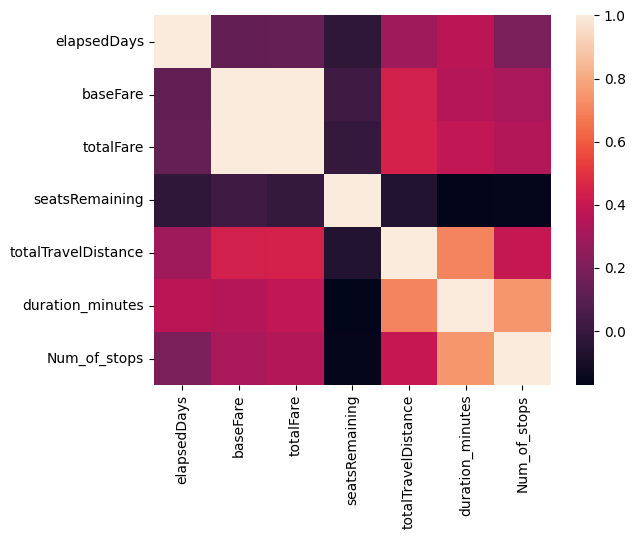

In [24]:
numeric_df = df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix);

In [43]:
features_to_drop = ['baseFare']
X = data_final.drop(['baseFare', 'totalFare','isRefundable'], axis=1)
y = data_final['totalFare']

In [44]:
X.shape

(600000, 39)

In [45]:
X.columns

Index(['elapsedDays', 'isBasicEconomy', 'isNonStop', 'seatsRemaining',
       'totalTravelDistance', 'duration_minutes', 'Num_of_stops',
       'startingAirport_ATL', 'startingAirport_BOS', 'startingAirport_CLT',
       'startingAirport_DEN', 'startingAirport_DFW', 'startingAirport_DTW',
       'startingAirport_EWR', 'startingAirport_IAD', 'startingAirport_JFK',
       'startingAirport_LAX', 'startingAirport_LGA', 'startingAirport_MIA',
       'startingAirport_OAK', 'startingAirport_ORD', 'startingAirport_PHL',
       'startingAirport_SFO', 'destinationAirport_ATL',
       'destinationAirport_BOS', 'destinationAirport_CLT',
       'destinationAirport_DEN', 'destinationAirport_DFW',
       'destinationAirport_DTW', 'destinationAirport_EWR',
       'destinationAirport_IAD', 'destinationAirport_JFK',
       'destinationAirport_LAX', 'destinationAirport_LGA',
       'destinationAirport_MIA', 'destinationAirport_OAK',
       'destinationAirport_ORD', 'destinationAirport_PHL',
       'destin

In [46]:
y

0         248.6
1         248.6
2         248.6
3         248.6
4         248.6
          ...  
599995    138.6
599996    151.6
599997    152.2
599998    167.1
599999    167.1
Name: totalFare, Length: 600000, dtype: float64

In [47]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

In [48]:
X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)

In [49]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)


In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import xgboost as xgb


In [40]:
def objective(trial):
    n_estimators = trial.suggest_int('n_estimators', 500, 2000)
    max_depth = trial.suggest_int('max_depth', 10, 50)

    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_train_log, y_train_log)

    y_pred_log = model.predict(X_test_log)
    y_pred = np.expm1(y_pred_log)
    r2 = mean_absolute_error(y_test, y_pred)
    return r2


In [ ]:
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler())
study.optimize(objective, n_trials=50)

[I 2025-09-10 21:40:37,009] A new study created in memory with name: no-name-25f632da-bf61-44b3-bb49-d74ff59c5573
[W 2025-09-10 21:44:26,703] Trial 0 failed with parameters: {'n_estimators': 919, 'max_depth': 23} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "c:\Users\samya\AppData\Local\Programs\Python\Python313\Lib\site-packages\optuna\study\_optimize.py", line 201, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\samya\AppData\Local\Temp\ipykernel_26744\4042322705.py", line 12, in objective
    model.fit(X_train_log, y_train_log)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\samya\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\samya\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\ensemble\_forest.py", line 486, in fit
    trees = Parallel(
    ...<2 lines>...
        prefer=

KeyboardInterrupt: 

In [63]:
print(f'Best trial R2 Score: {study.best_trial.value}')
print(f'Best Hyperparameters: {study.best_trial.params}')

Best trial R2 Score: 0.7474776967376042
Best Hyperparameters: {'n_estimators': 115, 'max_depth': 46}


In [51]:
model_final = RandomForestRegressor(
    n_estimators=115,
    max_depth=46,
    n_jobs=-1,
    random_state=42
)
model_final.fit(X_train_log,y_train_log)

,n_estimators,115
,criterion,'squared_error'
,max_depth,46
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [52]:
y_pred_log = model_final.predict(X_test_log)

In [53]:
y_pred = np.expm1(y_pred_log)

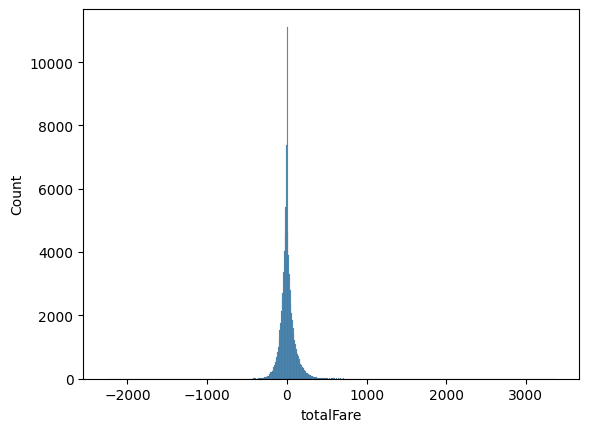

In [54]:
sns.histplot(y_test-y_pred)
plt.show()

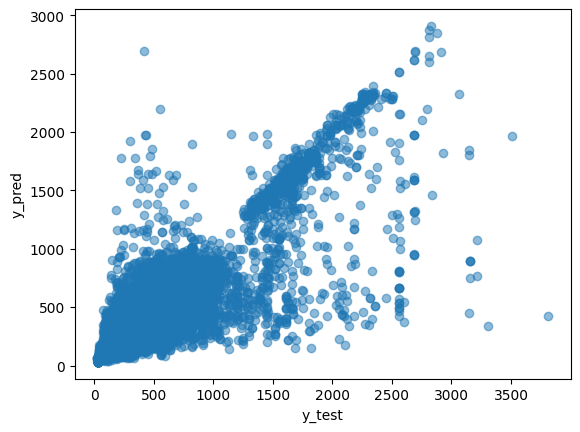

In [55]:
plt.scatter(y_test, y_pred, alpha = 0.5)
plt.xlabel("y_test")
plt.ylabel("y_pred")
plt.show()

In [56]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

In [57]:
print("R2 -> ", r2)
print("MAE -> ", mae)
print("RMSE -> ", rmse)

R2 ->  0.747423476009085
MAE ->  65.25501875698498
RMSE ->  120.81876562137829


In [42]:
import pandas as pd
import numpy as np

# Assuming:
# model = your trained model
# X_train = dataframe with your encoded features

# Get feature importances (use coef_ if linear regression)
importances = model_final.feature_importances_
feature_names = X_train.columns

# Create dataframe
fi_df = pd.DataFrame({'feature': feature_names, 'importance': importances})

# Group airports
fi_df['group'] = fi_df['feature'].apply(
    lambda x: 'StartingAirport' if x.startswith('startingAirport_') else
              'DestinationAirport' if x.startswith('destinationAirport_') else
              x
)

# Aggregate by group
agg_fi = fi_df.groupby('group')['importance'].sum().reset_index()

# Sort by importance
agg_fi = agg_fi.sort_values('importance', ascending=False)

print(agg_fi)

                 group  importance
9  totalTravelDistance    0.430247
3     duration_minutes    0.147112
8       seatsRemaining    0.099897
5       isBasicEconomy    0.098417
0   DestinationAirport    0.074632
2      StartingAirport    0.071344
1         Num_of_stops    0.071158
4          elapsedDays    0.006902
6            isNonStop    0.000287
7         isRefundable    0.000004


In [27]:
import pandas as pd

In [42]:
df2 = pd.read_csv(r"C:\Users\samya\OneDrive\Documents\GitHub\AirlinePricePredictor\truncated3.csv")


In [43]:
df = df2

In [44]:
import re

In [45]:
df["duration_minutes"] = df["travelDuration"].apply(parse_duration_to_minutes)
df["Num_of_Stops"] = df["segmentsAirlineName"].apply(categorize_stops)


In [46]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

encoded_values = encoder.fit_transform(df[['startingAirport','destinationAirport']])
new_col = encoder.get_feature_names_out(['startingAirport','destinationAirport'])

df_encoded = pd.DataFrame(encoded_values, columns=new_col, index=df.index)

data_final = pd.concat(
    [df.drop(columns=['startingAirport','destinationAirport']), df_encoded],
    axis = 1
)

In [47]:
df2 = data_final.dropna()
mean = (df2['totalTravelDistance']/df2['totalFare']).mean()
nan_mask = data_final['totalTravelDistance'].isna()
data_final.loc[nan_mask, 'totalTravelDistance'] = data_final.loc[nan_mask, 'totalFare'] * mean


In [48]:
data_final

,legId,searchDate,flightDate,fareBasisCode,travelDuration,elapsedDays,isBasicEconomy,isRefundable,isNonStop,baseFare,...,destinationAirport_EWR,destinationAirport_IAD,destinationAirport_JFK,destinationAirport_LAX,destinationAirport_LGA,destinationAirport_MIA,destinationAirport_OAK,destinationAirport_ORD,destinationAirport_PHL,destinationAirport_SFO
0,9ca0e81111c683bec1012473feefd28f,2022-04-16,2022-04-17,LA0NX0MC,PT2H29M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,98685953630e772a098941b71906592b,2022-04-16,2022-04-17,LA0NX0MC,PT2H30M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,98d90cbc32bfbb05c2fc32897c7c1087,2022-04-16,2022-04-17,LA0NX0MC,PT2H30M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,969a269d38eae583f455486fa90877b4,2022-04-16,2022-04-17,LA0NX0MC,PT2H32M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,980370cf27c89b40d2833a1d5afc9751,2022-04-16,2022-04-17,LA0NX0MC,PT2H34M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599995,d0b8831871406770573d3d47520d195e,2022-04-17,2022-06-14,SAA0OFEN,PT1H41M,0,False,False,True,115.35,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599996,b909fd1eb1b1caebff139147e7b5987e,2022-04-17,2022-06-14,WAA1JFEN,PT1H38M,0,False,False,True,127.44,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599997,aa1fac36237180027a6cd4aa25f829e9,2022-04-17,2022-06-14,XAVNA0BQ,PT8H57M,0,True,False,False,114.42,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
599998,0665c042ce293b362bf5fd04a42b7168,2022-04-17,2022-06-14,GVAGZNN1,PT5H10M,0,False,False,False,134.88,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [49]:
data_final['FlightEfficiency']= data_final['totalTravelDistance'] / data_final['duration_minutes']
data_final['duration_per_stop'] = data_final['duration_minutes'] / (data_final['Num_of_Stops'] + 1)

In [50]:
data_final.head()

,legId,searchDate,flightDate,fareBasisCode,travelDuration,elapsedDays,isBasicEconomy,isRefundable,isNonStop,baseFare,...,destinationAirport_JFK,destinationAirport_LAX,destinationAirport_LGA,destinationAirport_MIA,destinationAirport_OAK,destinationAirport_ORD,destinationAirport_PHL,destinationAirport_SFO,FlightEfficiency,duration_per_stop
0,9ca0e81111c683bec1012473feefd28f,2022-04-16,2022-04-17,LA0NX0MC,PT2H29M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.355705,149.0
1,98685953630e772a098941b71906592b,2022-04-16,2022-04-17,LA0NX0MC,PT2H30M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.313333,150.0
2,98d90cbc32bfbb05c2fc32897c7c1087,2022-04-16,2022-04-17,LA0NX0MC,PT2H30M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.313333,150.0
3,969a269d38eae583f455486fa90877b4,2022-04-16,2022-04-17,LA0NX0MC,PT2H32M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.230263,152.0
4,980370cf27c89b40d2833a1d5afc9751,2022-04-16,2022-04-17,LA0NX0MC,PT2H34M,0,False,False,True,217.67,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.149351,154.0


In [51]:
data_final = data_final.drop(['legId','searchDate','flightDate','fareBasisCode','travelDuration','segmentsDepartureTimeEpochSeconds','segmentsDepartureTimeRaw','segmentsArrivalTimeEpochSeconds','segmentsArrivalTimeRaw','segmentsArrivalAirportCode','segmentsDepartureAirportCode','segmentsAirlineName','segmentsAirlineCode','segmentsEquipmentDescription','segmentsDurationInSeconds','segmentsDistance','segmentsCabinCode','isRefundable','isNonStop'], axis = 1)

In [52]:
from sklearn.model_selection import train_test_split

In [53]:
X = data_final.drop(['baseFare', 'totalFare'], axis=1)
y = data_final['totalFare']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)


In [54]:
def objective(trial):
    n_estimators = trial.suggest_int('n_estimators', 500, 2000)
    max_depth = trial.suggest_int('max_depth', 10, 50)

    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_train_log, y_train_log)

    y_pred_log = model.predict(X_test_log)
    y_pred = np.expm1(y_pred_log)
    r2 = r2_score(y_test, y_pred)
    return r2


In [55]:
model_final = RandomForestRegressor(
    n_estimators=115,
    max_depth=46,
    n_jobs=-1,
    random_state=42
)
model_final.fit(X_train_log,y_train_log)

,n_estimators,115
,criterion,'squared_error'
,max_depth,46
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [56]:
y_pred_log = model_final.predict(X_test_log)
y_pred = np.expm1(y_pred_log)

In [57]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("R2 -> ", r2)
print("MAE -> ", mae)
print("RMSE -> ", rmse)

R2 ->  0.7422809884513495
MAE ->  65.63543898387483
RMSE ->  121.87501798645532


In [58]:
import pandas as pd
import numpy as np

# Assuming:
# model = your trained model
# X_train = dataframe with your encoded features

# Get feature importances (use coef_ if linear regression)
importances = model_final.feature_importances_
feature_names = X_train.columns

# Create dataframe
fi_df = pd.DataFrame({'feature': feature_names, 'importance': importances})

# Group airports
fi_df['group'] = fi_df['feature'].apply(
    lambda x: 'StartingAirport' if x.startswith('startingAirport_') else
              'DestinationAirport' if x.startswith('destinationAirport_') else
              x
)

# Aggregate by group
agg_fi = fi_df.groupby('group')['importance'].sum().reset_index()

# Sort by importance
agg_fi = agg_fi.sort_values('importance', ascending=False)

print(agg_fi)

                 group  importance
9  totalTravelDistance    0.401281
7       isBasicEconomy    0.098387
8       seatsRemaining    0.096738
1     FlightEfficiency    0.088136
0   DestinationAirport    0.071309
2         Num_of_Stops    0.070718
3      StartingAirport    0.066789
4     duration_minutes    0.059133
5    duration_per_stop    0.041110
6          elapsedDays    0.006399
